# EKF Target Estimation

This notebook tests the implemented extended kalman filter.

## Setup and Imports

In [1]:
%matplotlib widget

# standard library imports
import sys
import os
import logging
from pathlib import Path
from datetime import datetime

# third-party imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display

# Add the project root to the path to ensure imports work correctly
project_root = Path().absolute().parents[1]
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Import local modules
from utils import rosbag_utils, df_utils, plotting_utils
import multi_target_tracking as mtt

# Reload imports to ensure the latest code is used
import importlib
importlib.reload(sys.modules['utils'])
importlib.reload(sys.modules['multi_target_tracking'])

# Update references after reload
import utils.df_utils as dfu
import utils.plotting_utils as pu
import utils.rosbag_utils as rbu
import utils.sensor_sim as ss
import multi_target_tracking as mtt

Murty algorithm not available. Please install the murty package when using MHT tracking.


In [2]:
# plotting font sizes
pu.plt.rcParams.update({'font.size': 16,
                        'axes.labelsize': 16,
                        'axes.titlesize': 16,
                        'xtick.labelsize': 16,
                        'ytick.labelsize': 16,
                        'legend.fontsize': 16,
                        'figure.titlesize': 24})

## Configuration

In [3]:
## CONFIGURATION
BAG_PATH = os.path.join(project_root, 'data/gazebo_flight__2025-02-13-14-57-05.bag')
script_name = "02_EKF"
LOG_DIR = os.path.join(project_root, f'logs/{script_name}')
RESULTS_DIR = os.path.join(project_root, f'results/{script_name}')
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")
# Create directories if they don't exist
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

## LOGGING CONFIGURATION
# Configure logging to output to both console and file
log_file = LOG_DIR + f"/{script_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
# Create logger
logger = logging.getLogger()
logger.setLevel(logging.INFO)
# Clear any existing handlers
for handler in logger.handlers[:]: 
    logger.removeHandler(handler)
# Create file handler
file_handler = logging.FileHandler(log_file)
file_handler.setLevel(logging.DEBUG)
file_format = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
file_handler.setFormatter(file_format)
# Create console handler
console_handler = logging.StreamHandler()
console_handler.setLevel(logging.INFO)
console_format = logging.Formatter('%(levelname)s: %(message)s')
console_handler.setFormatter(console_format)
# Add handlers to logger
logger.addHandler(file_handler)
logger.addHandler(console_handler)
# Log to file and console
logger.info("Notebook started - EKF Target Estimation")

## ROSBAG READER
# Load the bag file
bag_path = Path(BAG_PATH)
if not bag_path.exists():
    raise FileNotFoundError(f"Rosbag file not found: {bag_path}")
bag_reader = rbu.load_rosbag(bag_path)
rbu.display_rosbag_info(bag_reader)

INFO: Notebook started - EKF Target Estimation


#################### Topics and message counts: ####################
Topic: /gazebo/model_states
    Message type: TopicInfo(msgtype='gazebo_msgs/msg/ModelStates', msgdef=MessageDefinition(format=<MessageDefinitionFormat.MSG: 1>, data='# broadcast all model states in world frame\nstring[] name                 # model names\ngeometry_msgs/Pose[] pose     # desired pose in world frame\ngeometry_msgs/Twist[] twist   # desired twist in world frame\n\n================================================================================\nMSG: geometry_msgs/Pose\n# A representation of pose in free space, composed of position and orientation. \nPoint position\nQuaternion orientation\n\n================================================================================\nMSG: geometry_msgs/Point\n# This contains the position of a point in free space\nfloat64 x\nfloat64 y\nfloat64 z\n\n================================================================================\nMSG: geometry_msgs/Quaternion\n# This 

## Data Extraction and Processing

Extract projection data and ground truth

In [4]:
# Define topics to analyze
topics = [
    "/machine_1/target_tracker/MTT/GT/target0",
    "/machine_1/object_detections/projected_to_world"
]

# Extract and process data
topic_data = {}
for topic in topics:
    data = rbu.create_df_from_bag(bag_reader, topic)
    topic_data[topic] = data

# print index of duplicate time values
# for topic, data in topic_data.items():
#     print(f"Duplicate time values in {topic}: {data['time'].duplicated().sum()}")
#     print(data[data['time'].duplicated()])

# # save data to csv
# for topic, data in topic_data.items():
#     data.to_csv(f"{LOG_DIR}/{topic.replace('/', '_')}.csv")

# reindex GT data to match the projected detections
topic_data["/machine_1/target_tracker/MTT/GT/target0"] = dfu.reindex_dataframe(topic_data["/machine_1/target_tracker/MTT/GT/target0"], 
                                                                               topic_data ["/machine_1/object_detections/projected_to_world"])
# estimate GT velocity (to compare with the estimated velocity from the tracker)
topic_data["/machine_1/target_tracker/MTT/GT/target0"] = dfu.estimate_velocity(topic_data["/machine_1/target_tracker/MTT/GT/target0"])
# clean duplicate time stamps in projected detections
topic_data["/machine_1/object_detections/projected_to_world"] = dfu.clean_duplicate_timestamps(topic_data["/machine_1/object_detections/projected_to_world"])

# print length of time values
for topic, data in topic_data.items():
    print(f"Length of time values in {topic}: {len(data)}")


INFO: Processing topic: '/machine_1/target_tracker/MTT/GT/target0' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Processing topic: '/machine_1/object_detections/projected_to_world' with message type: 'geometry_msgs/msg/PoseWithCovarianceStamped'
INFO: Cleaning duplicate timestamps in source_df...
INFO: Cleaning duplicate timestamps in target_df...
INFO: Using overlapping time range: [51.34, 140.84]
INFO: Interpolating source_df to target_df timestamps...
INFO: Interpolation complete.


Length of time values in /machine_1/target_tracker/MTT/GT/target0: 291
Length of time values in /machine_1/object_detections/projected_to_world: 291


In [5]:
## simulate sensor measurements using the GT data
timestamps, measurements = ss.simulate_position_sensor(topic_data["/machine_1/target_tracker/MTT/GT/target0"], white_noise_std=[0,0,0] ,random_walk=True, bounds=[5,5,6])
proj_timestamps, proj_measurements = dfu.dataframe_to_measurements(topic_data["/machine_1/object_detections/projected_to_world"])

# convert measurements to pandas DataFrame for visualization
measurements_df = dfu.measurements_to_dataframe(measurements, timestamps)

In [6]:
## test EKF with simulated measurements based on GT
results_sim = []
kf = mtt.KF3D_standalone()
for i, (time, measurement) in enumerate(zip(timestamps, measurements)):
    if i != measurements.__len__() - 1:
        kf.predict(delta_t=(timestamps[i+1] - time))
    kf.update(measurement, is_self=True)
    results_sim.append(mtt.PosVelMeasurement(
        position=kf.state[:3],
        velocity=kf.state[3:6],
        covariance=kf.cov[:6,:6]
        ))
    if i%1000 == 0:
        logger.info(f"Processed {i} measurements")

# post processing
results_sim = np.array(results_sim)
results_sim_df = dfu.measurements_to_dataframe(results_sim, timestamps)

INFO: Processed 0 measurements


In [7]:
## kalman filter with measurements from projected detections
results_proj = []
kf_proj = mtt.KF3D_standalone()
for i, (time, measurement) in enumerate(zip(proj_timestamps, proj_measurements)):
    if i != proj_measurements.__len__() - 1:
        kf_proj.predict(delta_t=(proj_timestamps[i+1] - time))
    kf_proj.update(measurement, is_self=True)
    results_proj.append(mtt.PosVelMeasurement(
        position=kf_proj.state[:3],
        velocity=kf_proj.state[3:6],
        covariance=kf_proj.cov[:6,:6]
        ))
    if i%1000 == 0:
        logger.info(f"Processed {i} measurements")

# post processing
results_proj = np.array(results_proj)
results_proj_df = dfu.measurements_to_dataframe(results_proj, proj_timestamps)

INFO: Processed 0 measurements


## Data Visualization

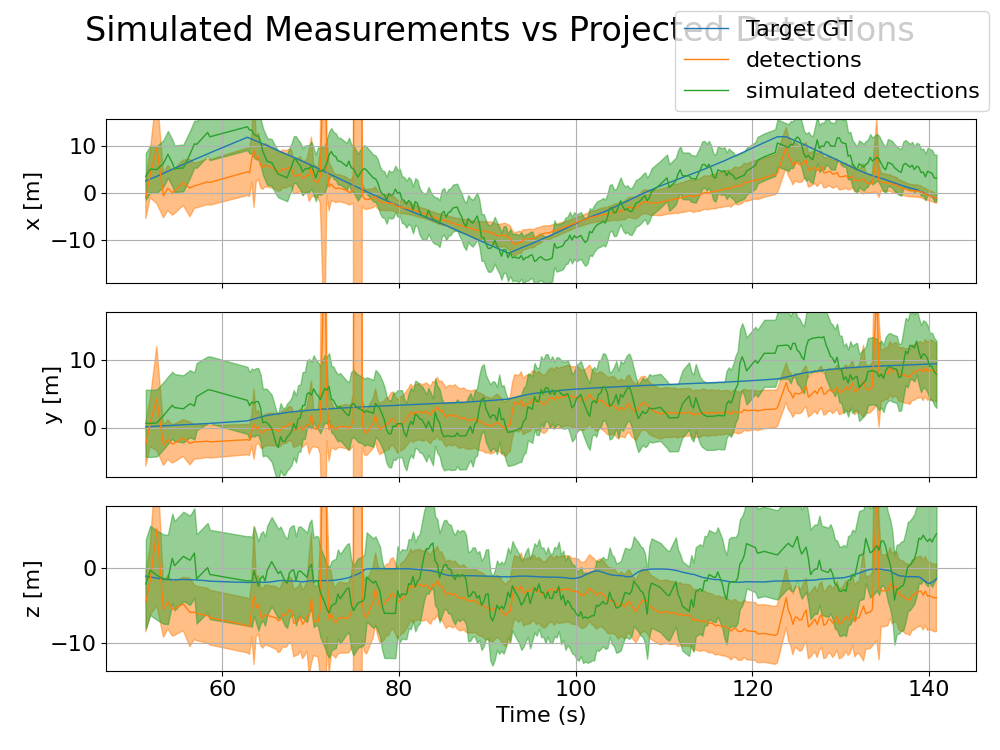

In [8]:
# compare simualted measurements with projected detections
fig_sim_proj = pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], label="Target GT")
pu.plot_xyz_over_time(topic_data["/machine_1/object_detections/projected_to_world"], fig=fig_sim_proj, label="detections", noisy_limits=True, show_uncertainty=True)
pu.plot_xyz_over_time(measurements_df, fig=fig_sim_proj, label="simulated detections", noisy_limits=True, show_uncertainty=True)
handles, labels = fig_sim_proj.axes[0].get_legend_handles_labels()
fig_sim_proj.legend(handles, labels, loc='upper right')
fig_sim_proj.suptitle("Simulated Measurements vs Projected Detections")
fig_sim_proj.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [9]:
# fig_sim_proj.savefig(os.path.join(PLOTS_DIR, "simulated_vs_projected_detections.svg"), dpi=600, bbox_inches='tight')

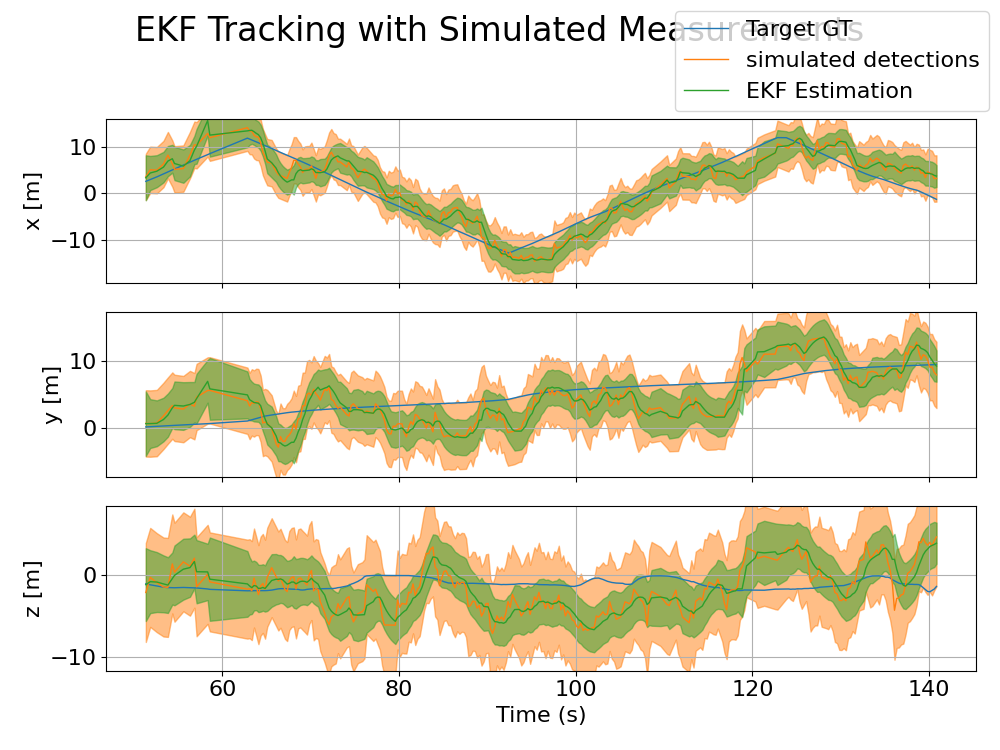

In [10]:
# EKF with simulated measurements
fig_ekf_sim = pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], label="Target GT")
pu.plot_xyz_over_time(measurements_df, fig=fig_ekf_sim, label="simulated detections", noisy_limits=True, show_uncertainty=True)
pu.plot_xyz_over_time(results_sim_df, fig=fig_ekf_sim, label="EKF Estimation", noisy_limits=True, show_uncertainty=True)
handles, labels = fig_ekf_sim.axes[0].get_legend_handles_labels()
fig_ekf_sim.legend(handles, labels, loc='upper right')
fig_ekf_sim.suptitle("EKF Tracking with Simulated Measurements")
fig_ekf_sim.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [11]:
# fig_ekf_sim.savefig(os.path.join(PLOTS_DIR, "ekf_tracking_simulated_measurements.svg"), dpi=600, bbox_inches='tight')

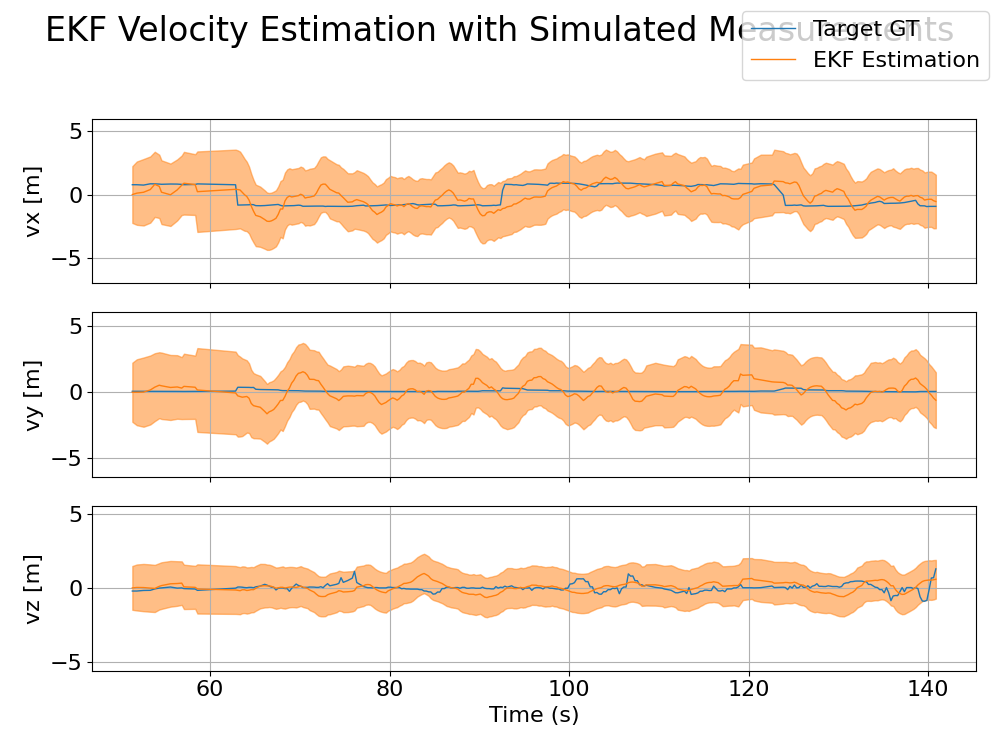

In [12]:
# EKF velocity estimation with simulated measurements
fig_ekf_sim_vel = pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], label="Target GT", coords=['vx', 'vy', 'vz'], cov_indices={'vx': 3, 'vy': 4, 'vz': 5})
pu.plot_xyz_over_time(results_sim_df, fig=fig_ekf_sim_vel, label="EKF Estimation", noisy_limits=True, show_uncertainty=True, coords=['vx', 'vy', 'vz'], cov_indices={'vx': 3, 'vy': 4, 'vz': 5})
handles, labels = fig_ekf_sim_vel.axes[0].get_legend_handles_labels()
fig_ekf_sim_vel.legend(handles, labels, loc='upper right')
fig_ekf_sim_vel.suptitle("EKF Velocity Estimation with Simulated Measurements")
fig_ekf_sim_vel.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [13]:
# fig_ekf_sim_vel.savefig(os.path.join(PLOTS_DIR, "ekf_velocity_estimation_simulated_measurements.svg"), dpi=600, bbox_inches='tight')

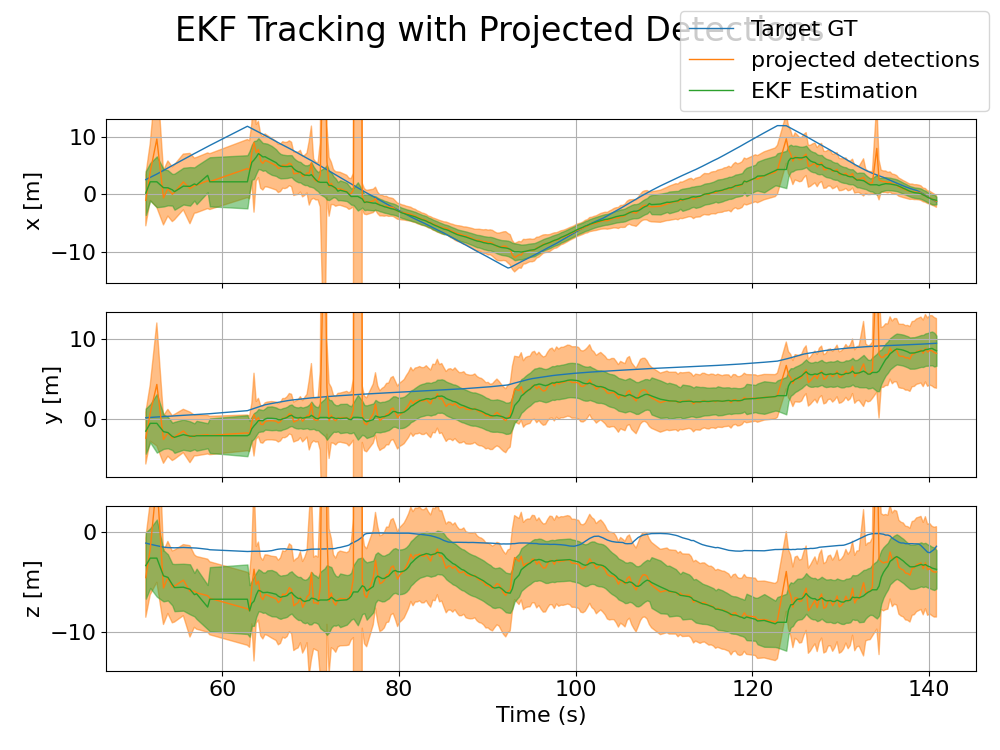

In [14]:
# EKF with projected detections
fig_ekf_proj = pu.plot_xyz_over_time(topic_data["/machine_1/target_tracker/MTT/GT/target0"], label="Target GT")
pu.plot_xyz_over_time(topic_data["/machine_1/object_detections/projected_to_world"], fig=fig_ekf_proj, label="projected detections", noisy_limits=True, show_uncertainty=True)
pu.plot_xyz_over_time(results_proj_df, fig=fig_ekf_proj, label="EKF Estimation", noisy_limits=True, show_uncertainty=True)
handles, labels = fig_ekf_proj.axes[0].get_legend_handles_labels()
fig_ekf_proj.legend(handles, labels, loc='upper right')
fig_ekf_proj.suptitle("EKF Tracking with Projected Detections")
fig_ekf_proj.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [15]:
# fig_ekf_proj.savefig(os.path.join(PLOTS_DIR, "ekf_tracking_projected_detections.svg"), dpi=600, bbox_inches='tight')

## Create an Animation

In [16]:
# # animate simulated detections and EKF results
# fig_anim_sim = pu.animate_2d_trajectory(topic_data["/machine_1/target_tracker/MTT/GT/target0"], measurements_df, results_sim_df, labels=["GT", "Simulated Measurements", "KF Estimation"])
# plt.show()

In [17]:
# animate proj detections and EKF results
# fig_anim_proj = pu.animate_2d_trajectory(topic_data["/machine_1/target_tracker/MTT/GT/target0"], topic_data["/machine_1/object_detections/projected_to_world"], results_proj_df, noisy_limits=True, labels=["GT", "Projected Detections", "KF Estimation"])
# plt.show()